# Arm 2 (`go_llm`) — what a language model predicts from the expression evidence

**Arm 2** gives a language model, for each gene, the same evidence arm 1 works from: which GO biological-process terms
are over- or under-represented among the cell types that express the gene (a statistics table, the gene's name is never
shown). The model answers with up to 10 GO term names. Those names are matched to real GO terms and compared with the
gene's own known annotation, with exactly the same outcome categories as the arm-1 notebook:

- **exact**: the predicted term is one of the gene's annotated terms
- **upward**: the prediction is a more general version of a true term
- **downward**: the prediction is a more specific version of a true term
- **no_match**: no relation to any true term

This notebook covers one condition: the evidence shown to the model is the real one (`evidence = true`), free-form
answers, one model. The control conditions (evidence from a different gene, or no evidence) have not been run, so the
question "does the model actually use the evidence?" is only approached indirectly, in Part 3.

Every number is recomputed from saved result files when the notebook runs. Metrics are explained where they first appear.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
FIG_DIR = ROOT / "notebooks" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
RES = ROOT / "data" / "go_experiment" / "match_summaries"
COND = "go_llm_v3_freeform_true__all"
sns.set_theme(style="whitegrid", font_scale=1.05)

# ---- one colour code for the whole notebook ------------------------------------------------------------------------------
# outcome of a predicted term (the same four colours as the arm-1 notebook)
COLORS = {"exact": "#009E73", "upward": "#0072B2", "downward": "#E69F00", "no_match": "#7F7F7F",
          "volume": "#4C72B0",          # a plain count, never an outcome
          "arm1": "#9467BD", "arm2": "#8C564B",   # which method (used only in the comparison)
          "valid": "#4C72B0", "invalid": "#D55E00", "duplicate": "#BBBBBB"}
ORDER = ["exact", "upward", "downward", "no_match"]


def save(fig, name: str) -> None:
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def qbin(s: pd.Series, q: int = 5) -> pd.Series:
    # equal-sized groups of a numeric property, labelled by their range
    cut = pd.qcut(s, q, duplicates="drop")
    lo = s.min()   # qcut widens the first interval slightly below the minimum; label with the real minimum
    return cut.map(lambda iv: f"{max(iv.left, lo):.3g} to {iv.right:.3g}")


from core.arm1_cache import load_arm1_cache
from core.arm2_cache import load_arm2_cache

c2 = load_arm2_cache()
P = c2.predictions                     # one row per valid predicted term of a finished gene
G = pd.read_parquet(RES / f"arm2_gene_table__{COND}.parquet")   # one row per finished gene
DET = pd.read_parquet(RES / f"arm2_match_details__{COND}.parquet")
R = json.loads((RES / f"arm2_results__{COND}.json").read_text())
arm1 = load_arm1_cache()

N_DONE, N_UNIVERSE = len(G), R["cost"]["n_universe"]
print(f"model: {c2.meta['models']}   code version: {c2.meta['code_hash_current']}")
print(f"finished genes: {N_DONE:,} of {N_UNIVERSE:,} scoreable ({N_DONE / N_UNIVERSE:.1%})   valid predicted terms: {len(P):,}")
assert len(P) == G[[f'n_{k}' for k in ORDER]].sum().sum() == R["n_valid_predictions"]

model: ['mistral-medium-3.5:latest']   code version: 5299e471e168
finished genes: 12,107 of 15,944 scoreable (75.9%)   valid predicted terms: 86,455


**A note on coverage.** Arm 2 runs the genes one after another in dataset order, so this notebook describes the genes
finished so far, not yet all scoreable genes. The separate coverage notebook (`arm2_go_llm_coverage.ipynb`) checks
whether the finished genes are a fair sample. Plots that split genes by expression breadth or annotation richness stay
meaningful even if coverage is uneven; pooled averages describe the finished genes only.

**Headline, stated plainly** (numbers are for the 12,107 genes finished at the time of this export; the text must be
refreshed when the data are):
- The model writes valid GO terms **reliably**: 95.5% of its answers resolve to a GO process term and 99.3% of those are
  the official name. No answer failed to parse.
- Its answers are **mostly not matches**: 95.0% of predicted terms have no relation to the gene's known annotation; 20.8%
  of genes get at least one real match among up to 7 terms, 4.5% an exact one.
- At **equal output size** (top 3 terms) it finds a real match for 12.1% of genes against 6.0% for arm 1, but **8.8 points
  of that 12.1% are what generic answers would also score**. The gene-specific part is clear for narrowly expressed
  genes and **absent for the most broadly expressed ones**.
- Its own **confidence and ranking carry only a weak signal**.

# Part 1 — Can the language model produce valid GO terms?

Before looking at whether the answers are *right*, the first question is whether they are *GO terms at all*. An answer
counts as **valid** when its text is exactly the name (or an exact synonym) of a GO biological-process term, so that it
can be matched to the gene's annotation. Nothing fuzzy is accepted: a near-miss wording is a different term.

## 1. How many of the model's answers are valid GO terms?

Left: every answer the model gave, split into valid, invalid (text is not a GO biological-process name) and duplicate
(a second name for a term already named, which is dropped). Right: for each finished gene, were all, some or none of
its answers valid.

answers: 90,532 in total; valid 95.5%, invalid 4.5%, duplicate 0.0%


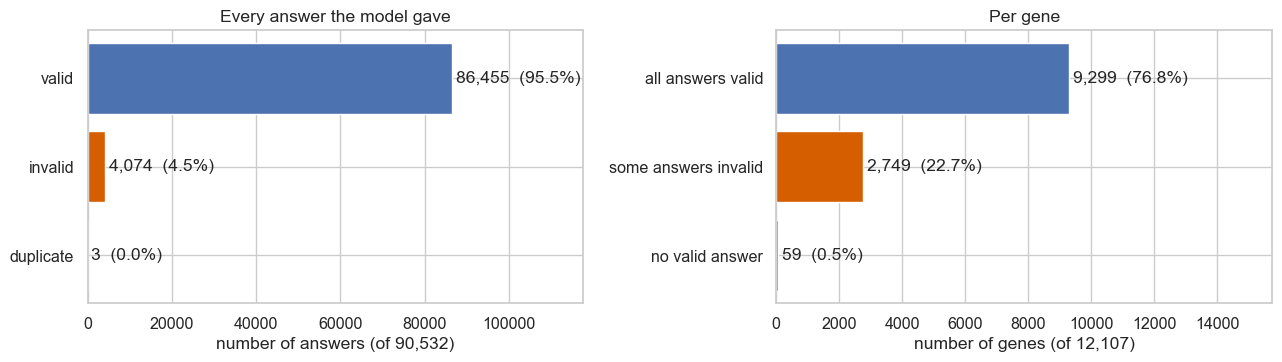

In [2]:
tot = {"valid": int(G["n_valid"].sum()), "invalid": int(G["n_invalid"].sum()), "duplicate": int(G["n_duplicate"].sum())}
n_raw = sum(tot.values())
print(f"answers: {n_raw:,} in total; valid {tot['valid'] / n_raw:.1%}, invalid {tot['invalid'] / n_raw:.1%}, duplicate {tot['duplicate'] / n_raw:.1%}")
state = pd.Series({
    "all answers valid": int(((G["n_invalid"] == 0) & (G["n_valid"] > 0)).sum()),
    "some answers invalid": int(((G["n_invalid"] > 0) & (G["n_valid"] > 0)).sum()),
    "no valid answer": int((G["n_valid"] == 0).sum())})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8))
s = pd.Series(tot)
bars = ax1.barh(s.index[::-1], s.values[::-1], color=[COLORS[k] for k in s.index[::-1]])
for b, v in zip(bars, s.values[::-1]):
    ax1.text(b.get_width() + n_raw * 0.01, b.get_y() + b.get_height() / 2, f"{v:,}  ({v / n_raw:.1%})", va="center")
ax1.set_xlim(0, n_raw * 1.3); ax1.set_xlabel(f"number of answers (of {n_raw:,})"); ax1.set_title("Every answer the model gave")
bars = ax2.barh(state.index[::-1], state.values[::-1], color=[COLORS["valid"], COLORS["invalid"], COLORS["invalid"]][::-1])
for b, v in zip(bars, state.values[::-1]):
    ax2.text(b.get_width() + N_DONE * 0.01, b.get_y() + b.get_height() / 2, f"{v:,}  ({v / N_DONE:.1%})", va="center")
ax2.set_xlim(0, N_DONE * 1.3); ax2.set_xlabel(f"number of genes (of {N_DONE:,})"); ax2.set_title("Per gene")
fig.tight_layout(); save(fig, "arm2_01_validity_overview"); plt.show()

## 2. How is validity spread over genes?

Left: how many valid terms each gene ended up with (the model may give up to 10). Right: the share of a gene's answers
that were valid. Many genes at 100% and a thin tail means invalid answers are the exception for most genes.

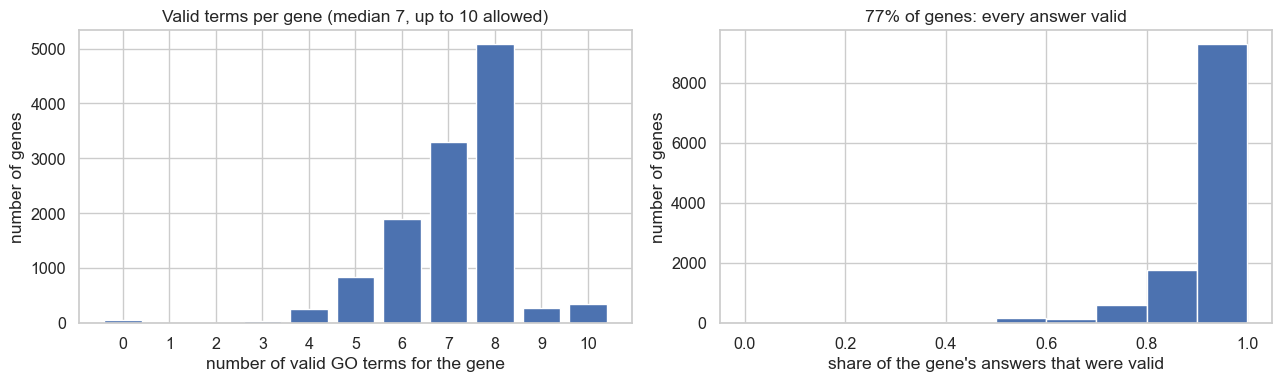

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
vc = G["n_valid"].value_counts().sort_index()
ax1.bar(vc.index, vc.values, color=COLORS["volume"])
ax1.set_xlabel("number of valid GO terms for the gene"); ax1.set_ylabel("number of genes"); ax1.set_xticks(range(0, int(vc.index.max()) + 1))
ax1.set_title(f"Valid terms per gene (median {G['n_valid'].median():.0f}, up to 10 allowed)")
share = (G["n_valid"] / G["n_predictions_raw"].replace(0, np.nan)).dropna()
ax2.hist(share, bins=np.linspace(0, 1, 11), color=COLORS["volume"], edgecolor="white")
ax2.set_xlabel("share of the gene's answers that were valid"); ax2.set_ylabel("number of genes")
ax2.set_title(f"{(share == 1).mean():.0%} of genes: every answer valid")
fig.tight_layout(); save(fig, "arm2_02_validity_per_gene"); plt.show()

## 3. Does the model write the official GO name?

For the valid answers: was the text exactly the official name of the term, a different form that still resolves (an
exact synonym or a spelling variant), or a GO ID? The "different form" answers are accepted, but they show how closely
the model reproduces GO wording from memory.

official GO name                              99.33%
another accepted form (synonym / spelling)     0.67%
written as a GO ID                             0.00%

most common other forms (written -> resolved to):
   136  'cellular protein metabolic process'  ->  'protein metabolic process'
    82  'regulation of synaptic transmission'  ->  'modulation of chemical synaptic transmission'
    82  'hematopoiesis'  ->  'hemopoiesis'
    77  'GABAergic synaptic transmission'  ->  'synaptic transmission, GABAergic'
    32  'glutamate signaling pathway'  ->  'glutamate receptor signaling pathway'
    29  'calcium ion-regulated exocytosis'  ->  'calcium-ion regulated exocytosis'
    20  'cellular modified amino acid metabolic process'  ->  'modified amino acid metabolic process'
    17  'ER to Golgi vesicle-mediated transport'  ->  'endoplasmic reticulum to Golgi vesicle-mediated transport'
    17  'interferon-gamma-mediated signaling pathway'  ->  'type II interferon-mediated signaling pathway'
 

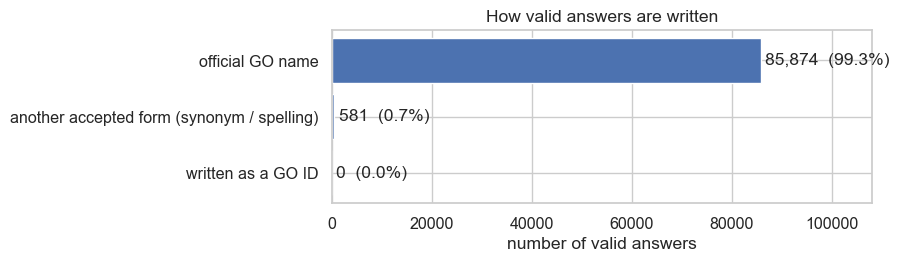

In [4]:
nf = R["name_forms"]
forms = pd.Series({"official GO name": nf["n_official_name"], "another accepted form (synonym / spelling)": nf["n_other_form"], "written as a GO ID": nf["n_written_as_id"]})
print((forms / forms.sum()).map("{:.2%}".format).to_string())
print("\nmost common other forms (written -> resolved to):")
for r in nf["top_other_forms"][:10]:
    print(f"  {r['n']:>4}  {r['written']!r}  ->  {r['resolved_to']!r}")
fig, ax = plt.subplots(figsize=(9, 2.8))
bars = ax.barh(forms.index[::-1], forms.values[::-1], color=COLORS["valid"])
for b, v in zip(bars, forms.values[::-1]):
    ax.text(b.get_width() + forms.sum() * 0.01, b.get_y() + b.get_height() / 2, f"{v:,}  ({v / forms.sum():.1%})", va="center")
ax.set_xlim(0, forms.sum() * 1.25); ax.set_xlabel("number of valid answers"); ax.set_title("How valid answers are written")
fig.tight_layout(); save(fig, "arm2_03_name_forms"); plt.show()

## 4. What are the invalid answers?

An invalid answer is not simply an invented term. Each invalid text is checked against all of GO, for diagnosis only
(nothing here changes how the runs were scored):
- **a real GO term, but a molecular function / cellular component**: right vocabulary, wrong kind of term
- **a related / broad / narrow synonym of a process term**, or **reworded, very close to an existing name**: the model
  meant an existing process, but wrote it in a form GO does not list as an exact name (often an older name, since GO
  renames terms over time)
- **function-type wording** ("... activity", "... binding"): not a process name
- **not a GO name**: nothing close in GO

In [5]:
inv = R["invalid"]
if inv is None:
    print("The invalid-answer table is not in the cache (the export on the server predates it). "
          "Re-run scripts/export_arm2_cache.py there, copy the arm2_invalid parquet file here, "
          "then re-run scripts/analyze_arm2_results.py. This plot is skipped.")
else:
    bc = pd.Series(inv["by_class_answers"]).sort_values()
    print(f"{inv['n_answers']:,} invalid answers, {inv['n_distinct']:,} different texts")
    colors = [COLORS["invalid"] if ("not a GO name" in k or "function-type" in k) else COLORS["duplicate"] for k in bc.index]
    fig, ax = plt.subplots(figsize=(11, 0.55 * len(bc) + 1.5))
    bars = ax.barh([k if len(k) < 70 else k[:67] + "..." for k in bc.index], bc.values, color=COLORS["invalid"])
    for b, v in zip(bars, bc.values):
        ax.text(b.get_width() + bc.max() * 0.01, b.get_y() + b.get_height() / 2, f"{v:,}  ({v / bc.sum():.1%})", va="center")
    ax.set_xlim(0, bc.max() * 1.25); ax.set_xlabel("number of invalid answers"); ax.set_title("What the invalid answers are")
    fig.tight_layout(); save(fig, "arm2_04_invalid_answers"); plt.show()
    print("\nmost frequent invalid texts:")
    for r in inv["top_strings"][:15]:
        near = f"  (nearest GO name: {r['nearest_go_name']!r})" if r["nearest_go_name"] else ""
        print(f"  {r['n']:>4}  {r['term']!r}  [{r['class']}]{near}")

The invalid-answer table is not in the cache (the export on the server predates it). Re-run scripts/export_arm2_cache.py there, copy the arm2_invalid parquet file here, then re-run scripts/analyze_arm2_results.py. This plot is skipped.


## 5. Does validity depend on the gene?

The share of valid answers within five equal-sized groups of genes, by expression breadth (share of cell types
expressing the gene) and by annotation richness (number of known true GO terms). Flat bars mean the model is
equally reliable for every kind of gene; a trend would mean validity itself is biased.

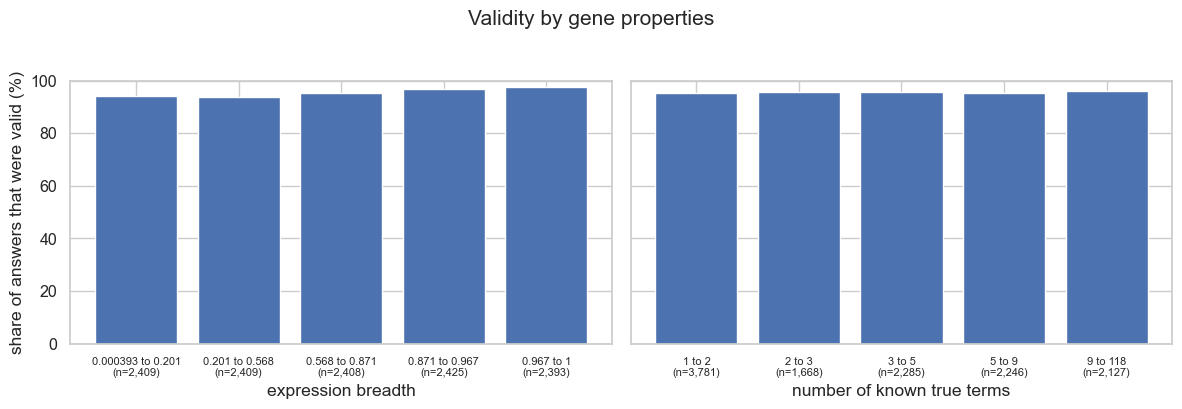

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, col, title in [(axes[0], "breadth", "expression breadth"), (axes[1], "n_direct_terms", "number of known true terms")]:
    d = G.dropna(subset=[col]).copy(); d["bin"] = qbin(d[col])
    t = d.groupby("bin", observed=True).agg(valid=("n_valid", "sum"), raw=("n_predictions_raw", "sum"), n=("gene_id", "size"))
    t = t.loc[sorted(t.index, key=lambda s: float(s.split(" to ")[0]))]
    ax.bar(range(len(t)), t["valid"] / t["raw"] * 100, color=COLORS["valid"])
    ax.set_xticks(range(len(t))); ax.set_xticklabels([f"{i}\n(n={n:,})" for i, n in zip(t.index, t["n"])], fontsize=8)
    ax.set_xlabel(title); ax.set_ylim(0, 100)
axes[0].set_ylabel("share of answers that were valid (%)")
fig.suptitle("Validity by gene properties", y=1.02)
fig.tight_layout(); save(fig, "arm2_05_validity_by_gene_property"); plt.show()

## 6. Does the model copy the evidence or add something?

The evidence table lists 52 GO terms. A predicted term that is **in the table** can simply be read off it; a term
**outside the table** is something the model brought itself. Left: for each gene, the share of its valid predicted
terms that appear in the evidence table. Right: how often terms of each kind turn out to be a real match (any of exact,
upward, downward) and an exact match.

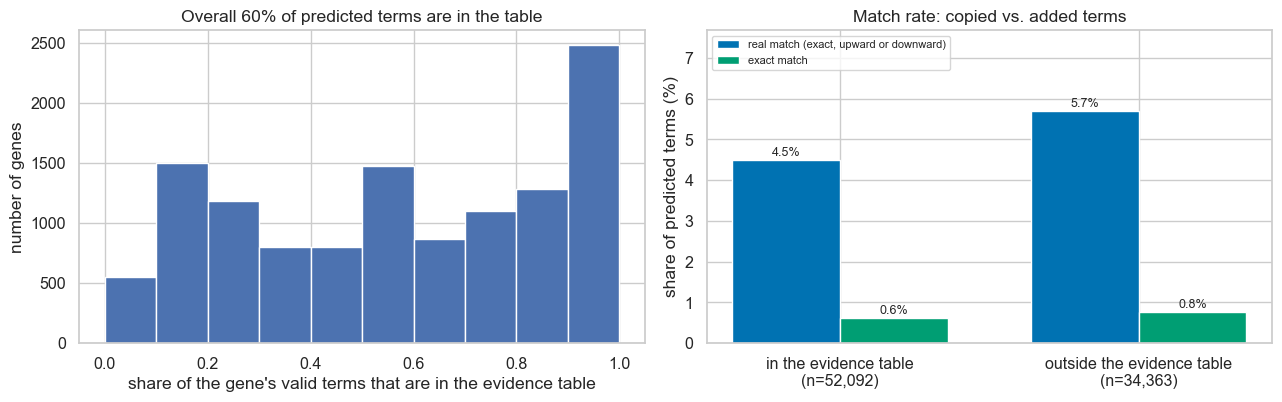

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
ax1.hist(G["frac_in_table"].dropna(), bins=np.linspace(0, 1, 11), color=COLORS["volume"], edgecolor="white")
ax1.set_xlabel("share of the gene's valid terms that are in the evidence table"); ax1.set_ylabel("number of genes")
ax1.set_title(f"Overall {P['in_table'].mean():.0%} of predicted terms are in the table")
rows = []
for flag, name in [(True, "in the evidence table"), (False, "outside the evidence table")]:
    s = P[P["in_table"] == flag]
    rows.append({"group": f"{name}\n(n={len(s):,})", "real match": (s["kind"] != "no_match").mean(), "exact match": (s["kind"] == "exact").mean()})
t = pd.DataFrame(rows).set_index("group")
x = np.arange(len(t)); w = 0.36
ax2.bar(x - w / 2, t["real match"] * 100, width=w, color=COLORS["upward"], label="real match (exact, upward or downward)")
ax2.bar(x + w / 2, t["exact match"] * 100, width=w, color=COLORS["exact"], label="exact match")
for i, (a, b) in enumerate(zip(t["real match"], t["exact match"])):
    ax2.text(i - w / 2, a * 100 + 0.1, f"{a:.1%}", ha="center", fontsize=9); ax2.text(i + w / 2, b * 100 + 0.1, f"{b:.1%}", ha="center", fontsize=9)
ax2.set_xticks(x); ax2.set_xticklabels(t.index); ax2.set_ylabel("share of predicted terms (%)"); ax2.legend(fontsize=8, loc="upper left")
ax2.set_ylim(0, t["real match"].max() * 100 * 1.35)
ax2.set_title("Match rate: copied vs. added terms")
fig.tight_layout(); save(fig, "arm2_06_copy_vs_infer"); plt.show()

## Part 1 summary

Each bullet gives what the plot shows and what it means for the project (12,107 finished genes, 90,532 answers).

- **Plot 1, validity overview.** 95.5% of answers are valid GO terms, 4.5% (4,074) are not, 3 are duplicates. 76.8% of genes
  have only valid answers, 22.7% have some invalid ones and 59 genes (0.5%) have none.
  *For us:* the model produces GO terms reliably: about 1 answer in 22 is lost, and there were no formatting failures
  (no retries, no unparseable answers). The 59 genes with no valid answer are few but a systematic failure worth a look.
- **Plot 2, validity per gene.** The typical gene gets 7 valid terms (most between 6 and 8; the limit of 10 is rarely
  reached) and 77% of genes have every answer valid.
  *For us:* the output size is stable at about 7 terms per gene, which is the number to use when comparing with arm 1.
- **Plot 3, how names are written.** 99.3% of valid answers are the official GO name and 0.7% (581) another accepted form,
  none a GO ID. The recurring forms are older or alternative names, for example "hematopoiesis" for "hemopoiesis" (82) and
  "cellular protein metabolic process" for "protein metabolic process" (136).
  *For us:* the model reproduces GO wording from memory almost exactly, and what it gets slightly wrong is a handful of
  recurring synonyms rather than random variation.
- **Plot 4, what the invalid answers are.** Not yet available: the export on the server predates the invalid-answer table.
  Re-run the export there, copy the new file here and re-run the analysis to fill this in.
- **Plot 5, validity by gene properties.** The valid share is about 93-97% in every group, slightly higher for broadly
  expressed genes and flat by number of known true terms.
  *For us:* validity does not depend on how well a gene is annotated, so it will not bias the match results.
- **Plot 6, copying or adding.** 60% of predicted terms are in the evidence table and 40% are outside it; genes range from
  almost pure copying to almost none. Terms outside the table are real matches 5.7% of the time (0.8% exact), terms taken
  from the table 4.5% (0.6% exact).
  *For us:* the model does not just read the table back, and the terms it adds are at least as often right as the copied
  ones. Whether the model uses the evidence at all, rather than writing plausible GO terms by itself, needs the control
  condition (see Part 3).

# Part 2 — Headline results

The same views as Part 1 of the arm-1 notebook, so the two can be read side by side.

## 7. Where does the gene population go? (funnel)

Starting from the finished genes: how many get at least one valid GO term, at least one real match (exact, upward or
downward), and at least one exact match.

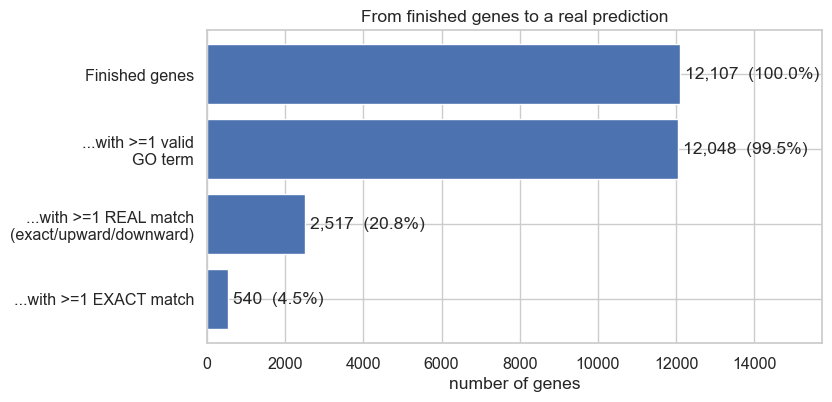

In [8]:
funnel = pd.Series({"Finished genes": N_DONE, "...with >=1 valid\nGO term": int((G["n_valid"] > 0).sum()),
                    "...with >=1 REAL match\n(exact/upward/downward)": int(G["any_match"].sum()), "...with >=1 EXACT match": int(G["any_exact"].sum())})
fig, ax = plt.subplots(figsize=(8.5, 4.2))
bars = ax.barh(funnel.index[::-1], funnel.values[::-1], color=COLORS["volume"])
for b, v in zip(bars, funnel.values[::-1]):
    ax.text(b.get_width() + N_DONE * 0.01, b.get_y() + b.get_height() / 2, f"{v:,}  ({v / N_DONE:.1%})", va="center")
ax.set_xlim(0, N_DONE * 1.3); ax.set_xlabel("number of genes"); ax.set_title("From finished genes to a real prediction")
fig.tight_layout(); save(fig, "arm2_07_funnel"); plt.show()

## 8. What does a predicted term turn out to be? (outcome breakdown)

A bar chart on a linear scale (a pie chart or a log scale would hide how dominant `no_match` is, which is the point).

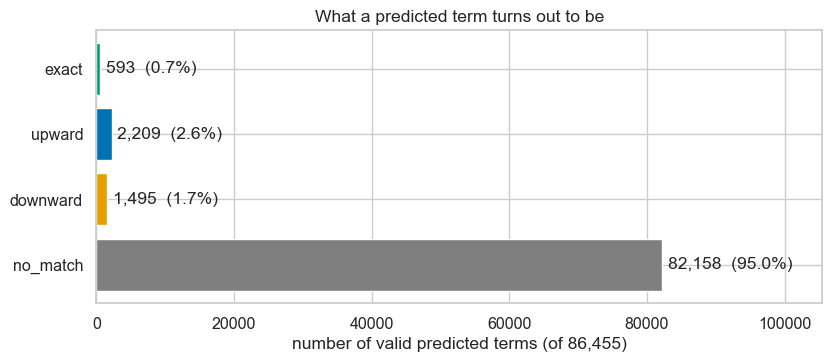

In [9]:
cnt = P["kind"].value_counts().reindex(ORDER)
tot_p = cnt.sum()
fig, ax = plt.subplots(figsize=(8.5, 3.8))
bars = ax.barh(cnt.index[::-1], cnt.values[::-1], color=[COLORS[k] for k in cnt.index[::-1]])
for b, v in zip(bars, cnt.values[::-1]):
    ax.text(b.get_width() + tot_p * 0.01, b.get_y() + b.get_height() / 2, f"{v:,}  ({v / tot_p:.1%})", va="center")
ax.set_xlim(0, tot_p * 1.22); ax.set_xlabel(f"number of valid predicted terms (of {tot_p:,})"); ax.set_title("What a predicted term turns out to be")
fig.tight_layout(); save(fig, "arm2_08_outcomes"); plt.show()

## 9. Among the real matches, how close are they?

For the non-exact matches, the number of GO edges between the prediction and the true term (1 = direct parent or
child). Edges are a coarse measure, since one edge can be a small or a large step in specificity (Plot 20 shows the
information-content view).

kind     upward  downward
bin                      
d=1         732       619
d=2         695       459
d=3         383       294
3<d<=5      354       118
5<d<=10      45         5
d>10          0         0
share of upward matches within 2 edges: 65%; downward: 72%


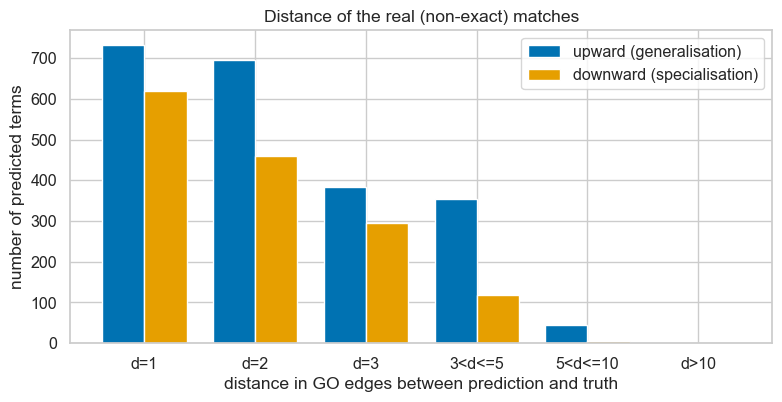

In [10]:
m = P[P["kind"].isin(["upward", "downward"])].copy()
edges = [1, 2, 3, 5, 10]
def bl(d):
    prev = 0
    for e in edges:
        if d <= e:
            return f"d={int(d)}" if e - prev <= 1 else f"{prev}<d<={e}"
        prev = e
    return f"d>{edges[-1]}"
labels = ["d=1", "d=2", "d=3", "3<d<=5", "5<d<=10", "d>10"]
m["bin"] = m["distance"].map(bl)
t = m.groupby(["bin", "kind"]).size().unstack(fill_value=0).reindex(index=labels, columns=["upward", "downward"], fill_value=0)
print(t.to_string()); print(f"share of upward matches within 2 edges: {(m[m.kind=='upward']['distance'] <= 2).mean():.0%}; downward: {(m[m.kind=='downward']['distance'] <= 2).mean():.0%}")
fig, ax = plt.subplots(figsize=(8, 4.2)); x = np.arange(len(t)); w = 0.38
ax.bar(x - w / 2, t["upward"], width=w, color=COLORS["upward"], label="upward (generalisation)")
ax.bar(x + w / 2, t["downward"], width=w, color=COLORS["downward"], label="downward (specialisation)")
ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_xlabel("distance in GO edges between prediction and truth"); ax.set_ylabel("number of predicted terms")
ax.set_title("Distance of the real (non-exact) matches"); ax.legend()
fig.tight_layout(); save(fig, "arm2_09_match_distance"); plt.show()

## 10. How many terms does a typical gene get, compared with arm 1?

Arm 1 only reports terms that pass its significance test, which is often none. The model answers up to 10 terms for
every gene. Comparing the two on equal terms later (Part 5) therefore uses the top 1, top 3 and top 10 terms of each,
never the full lists against each other.

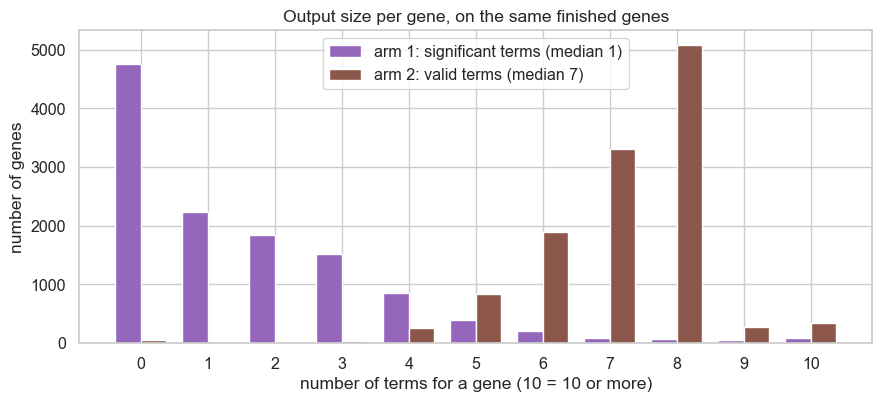

In [11]:
ids = set(G["gene_id"]); a1 = arm1.sig[arm1.sig["gene_id"].isin(ids)].groupby("gene_id").size().reindex(G["gene_id"]).fillna(0).astype(int)
fig, ax = plt.subplots(figsize=(9, 4.2))
mx = 10; xs = np.arange(0, mx + 1); w = 0.38
v2 = G["n_valid"].clip(upper=mx).value_counts().reindex(xs, fill_value=0); v1 = a1.clip(upper=mx).value_counts().reindex(xs, fill_value=0)
ax.bar(xs - w / 2, v1.values, width=w, color=COLORS["arm1"], label=f"arm 1: significant terms (median {a1.median():.0f})")
ax.bar(xs + w / 2, v2.values, width=w, color=COLORS["arm2"], label=f"arm 2: valid terms (median {G['n_valid'].median():.0f})")
ax.set_xlabel("number of terms for a gene (10 = 10 or more)"); ax.set_ylabel("number of genes"); ax.set_xticks(xs); ax.legend()
ax.set_title("Output size per gene, on the same finished genes")
fig.tight_layout(); save(fig, "arm2_10_terms_per_gene"); plt.show()

## 11. Is this a structural limitation? (oracle ceiling against match)

For every gene, the **oracle ceiling** is the best score *any* method could reach using only the 52-term vocabulary
of the evidence (from an earlier analysis). If genes that got a match tend to have a higher ceiling, the result is
tied to what the evidence vocabulary can express for the gene, not to how well the model reasons.

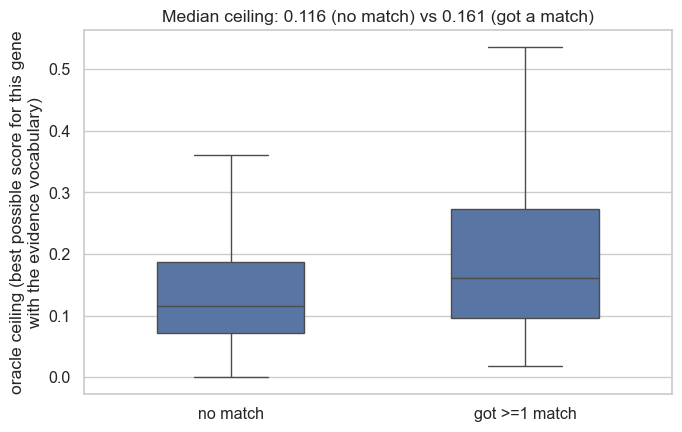

In [12]:
d = G.dropna(subset=["f1_top1"]).copy(); d["group"] = np.where(d["any_match"] == 1, "got >=1 match", "no match")
med = d.groupby("group")["f1_top1"].median()
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.boxplot(data=d, x="group", y="f1_top1", order=["no match", "got >=1 match"], color=COLORS["volume"], width=0.5, ax=ax, showfliers=False)
ax.set_xlabel(""); ax.set_ylabel("oracle ceiling (best possible score for this gene\nwith the evidence vocabulary)")
ax.set_title(f"Median ceiling: {med['no match']:.3f} (no match) vs {med['got >=1 match']:.3f} (got a match)")
fig.tight_layout(); save(fig, "arm2_11_ceiling_vs_match"); plt.show()

## Part 2 summary

- **Plot 7, funnel.** Of 12,107 finished genes, 12,048 (99.5%) get at least one valid term, 2,517 (20.8%) at least one real
  match and 540 (4.5%) an exact match.
  *For us:* about one gene in five gets any real match and one in 22 an exact match, with up to 7 terms each. Arm 1 reaches
  7.7% and 1.2% on all genes with a median of 1 term, so the two are not comparable until the output size is equalised (Part 5).
- **Plot 8, outcome breakdown.** Of 86,455 predicted terms, 95.0% are no_match, 2.6% upward, 1.7% downward and 0.7% exact.
  *For us:* the mix is almost the same as arm 1's (93.9 / 3.0 / 2.4 / 0.7). Per predicted term the model is not more accurate
  than arm 1 (5.0% of its terms are a real match against 6.1% of arm 1's significant terms); its higher match rate per gene
  comes from naming more terms per gene.
- **Plot 9, distance of the matches.** 65% of upward and 72% of downward matches are within 2 GO edges; none is more than 10
  away.
  *For us:* as for arm 1, the matches are mostly close ones, so the match rule is not carried by loose relations.
- **Plot 10, terms per gene against arm 1.** Arm 1 reports a median of 1 term and nothing for 39% of these genes; the model
  reports a median of 7.
  *For us:* comparisons have to use equal-sized lists (top 1, 3, 10), which is what Part 5 does.
- **Plot 11, ceiling against match.** The median oracle ceiling is 0.161 for genes with a match and 0.116 for genes without.
  *For us:* matches occur where the 52-term evidence vocabulary can express the gene better, as in arm 1, so part of the limit
  comes from the setup and not from the method.

# Part 3 — Are the answers specific to the gene, or generic?

A model can score matches by saying things that fit *many* genes ("immune response", "cell differentiation"). To see how
much of the match rate is that, each gene's predicted terms are scored against the true terms of **five other genes with
a similar expression breadth** and averaged (the "shuffled baseline"). If the real gene's matches are well above it, the
answers are specific to the gene. This is a stand-in computed without the model; the proper control (give the model the
evidence of a different gene) has not been run.

## 12. Real matches against the shuffled baseline

For each outcome kind: the number of predicted terms with that outcome, against the number expected when the same
predictions are scored against other genes' true terms. The label shows observed divided by expected.

          observed  expected_if_shuffled  ratio
exact          593                 317.0   1.87
upward        2209                1555.0   1.42
downward      1495                1085.0   1.38
no_match     82148               83488.0   0.98


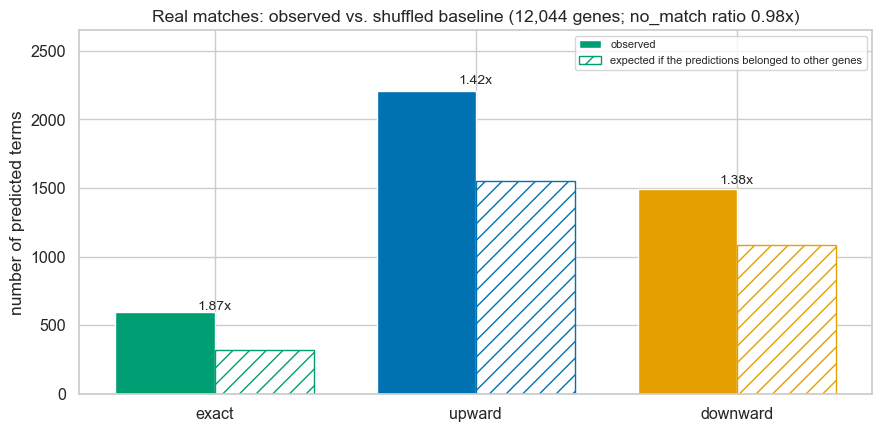

In [13]:
S = G.dropna(subset=["shuf_exact"]).copy()
ids_s = set(S["gene_id"]); Ps = P[P["gene_id"].isin(ids_s)]
obs = Ps["kind"].value_counts().reindex(ORDER).fillna(0)
exp = pd.Series({k: S[f"shuf_{k}"].sum() for k in ORDER})
print(pd.DataFrame({"observed": obs, "expected_if_shuffled": exp.round(0), "ratio": (obs / exp).round(2)}).to_string())
REAL = ["exact", "upward", "downward"]   # no_match (about 95% of terms) would dwarf these; its ratio is printed above
fig, ax = plt.subplots(figsize=(9, 4.5)); x = np.arange(len(REAL)); w = 0.38
ax.bar(x - w / 2, obs[REAL].values, width=w, color=[COLORS[k] for k in REAL], label="observed")
ax.bar(x + w / 2, exp[REAL].values, width=w, color="white", edgecolor=[COLORS[k] for k in REAL], hatch="//", label="expected if the predictions belonged to other genes")
for i, k in enumerate(REAL):
    ax.text(i, max(obs[k], exp[k]) * 1.02 + 5, f"{obs[k] / exp[k]:.2f}x", ha="center", fontsize=10)
ax.set_xticks(x); ax.set_xticklabels(REAL); ax.set_ylabel("number of predicted terms")
ax.set_ylim(0, max(obs[REAL].max(), exp[REAL].max()) * 1.2); ax.legend(loc="upper right", fontsize=8)
ax.set_title(f"Real matches: observed vs. shuffled baseline ({len(S):,} genes; no_match ratio {obs['no_match'] / exp['no_match']:.2f}x)")
fig.tight_layout(); save(fig, "arm2_12_observed_vs_shuffled"); plt.show()

## 13. The same comparison by expression breadth

The share of genes with at least one real match, for the model's answers (observed) and for the shuffled baseline, in
five equal-sized groups of expression breadth. A gap that stays open in every group means the answers are
gene-specific for narrow and broad genes alike.

                   observed  shuffled     n
bin                                        
0.000393 to 0.201      27.6      15.1  2409
0.201 to 0.568         23.8      16.3  2409
0.568 to 0.871         16.6      12.7  2408
0.871 to 0.967         16.5      14.4  2425
0.967 to 1             19.9      20.6  2393


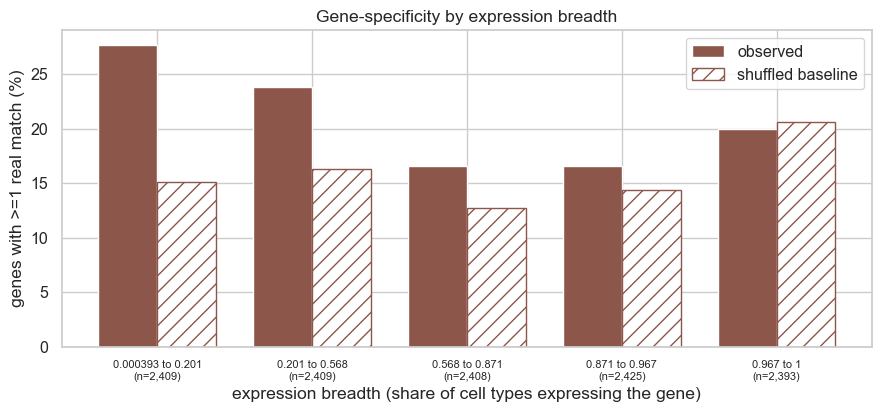

In [14]:
d = S.dropna(subset=["breadth"]).copy(); d["bin"] = qbin(d["breadth"])
t = d.groupby("bin", observed=True).agg(observed=("any_match", "mean"), shuffled=("shuf_any_match", "mean"), n=("gene_id", "size"))
t = t.loc[sorted(t.index, key=lambda s: float(s.split(" to ")[0]))]
print((t[["observed", "shuffled"]] * 100).round(1).assign(n=t["n"]).to_string())
fig, ax = plt.subplots(figsize=(9, 4.3)); x = np.arange(len(t)); w = 0.38
ax.bar(x - w / 2, t["observed"] * 100, width=w, color=COLORS["arm2"], label="observed")
ax.bar(x + w / 2, t["shuffled"] * 100, width=w, color="white", edgecolor=COLORS["arm2"], hatch="//", label="shuffled baseline")
ax.set_xticks(x); ax.set_xticklabels([f"{i}\n(n={n:,})" for i, n in zip(t.index, t["n"])], fontsize=8)
ax.set_xlabel("expression breadth (share of cell types expressing the gene)"); ax.set_ylabel("genes with >=1 real match (%)"); ax.legend()
ax.set_title("Gene-specificity by expression breadth")
fig.tight_layout(); save(fig, "arm2_13_shuffled_by_breadth"); plt.show()

## Part 3 summary

- **Plot 12, observed against the shuffled baseline.** Scored against other genes of similar breadth, the same predictions
  would give 317 exact matches instead of the observed 593 (1.87x), 1,555 upward instead of 2,209 (1.42x) and 1,085 downward
  instead of 1,495 (1.38x); the no_match count is 0.98x.
  *For us:* even with generic answers about 53% of the exact, 70% of the upward and 73% of the downward matches would be
  expected. Only a minority of the matches is evidence that the model said something specific to the gene.
- **Plot 13, by expression breadth.** For the narrowest genes 27.6% have a real match against 15.1% for the baseline, and for
  the next group 23.8% against 16.3%. In the middle groups the gap is small (16.6 against 12.7 and 16.5 against 14.4), and
  for the most broadly expressed genes there is none (19.9% against 20.6%).
  *For us:* the model carries gene-specific information for narrowly expressed genes, but for broad genes its matches are
  no better than generic answers. A match rate pooled over all genes therefore overstates what the model knows about
  broad genes. The shuffled baseline is a proxy; running the model on a different gene's evidence is the proper control.

# Part 4 — What characterizes a match?

The same questions as Part 2 of the arm-1 notebook, plus two that only make sense for a language model: whether its own
confidence says anything, and how varied its vocabulary is.

## 14. Does expression breadth predict getting a match?

For five equal-sized groups of expression breadth: the share of genes with at least one real match, and with at least
one exact match.

                   match  exact     n
bin                                  
0.000393 to 0.201   27.6    8.7  2409
0.201 to 0.568      23.8    5.5  2409
0.568 to 0.871      16.6    2.8  2408
0.871 to 0.967      16.5    2.6  2425
0.967 to 1          19.9    2.8  2393


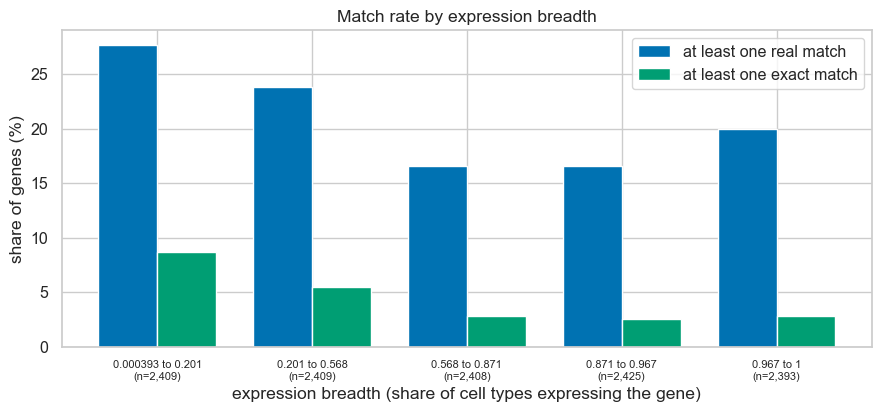

In [15]:
d = G.dropna(subset=["breadth"]).copy(); d["bin"] = qbin(d["breadth"])
t = d.groupby("bin", observed=True).agg(match=("any_match", "mean"), exact=("any_exact", "mean"), n=("gene_id", "size"))
t = t.loc[sorted(t.index, key=lambda s: float(s.split(" to ")[0]))]
print((t[["match", "exact"]] * 100).round(1).assign(n=t["n"]).to_string())
fig, ax = plt.subplots(figsize=(9, 4.3)); x = np.arange(len(t)); w = 0.38
ax.bar(x - w / 2, t["match"] * 100, width=w, color=COLORS["upward"], label="at least one real match")
ax.bar(x + w / 2, t["exact"] * 100, width=w, color=COLORS["exact"], label="at least one exact match")
ax.set_xticks(x); ax.set_xticklabels([f"{i}\n(n={n:,})" for i, n in zip(t.index, t["n"])], fontsize=8)
ax.set_xlabel("expression breadth (share of cell types expressing the gene)"); ax.set_ylabel("share of genes (%)"); ax.legend()
ax.set_title("Match rate by expression breadth")
fig.tight_layout(); save(fig, "arm2_14_breadth"); plt.show()

## 15. How specific are the predicted terms?

**Information content (IC)** = -ln(fraction of genes carrying the term): a rarer, more specific term has a higher IC.
Box plots of the IC of predicted terms by outcome. If exact matches clustered at low IC, the model's wins would be cheap,
generic terms.

kind
exact       3.88
upward      2.92
downward    5.57
no_match    4.93


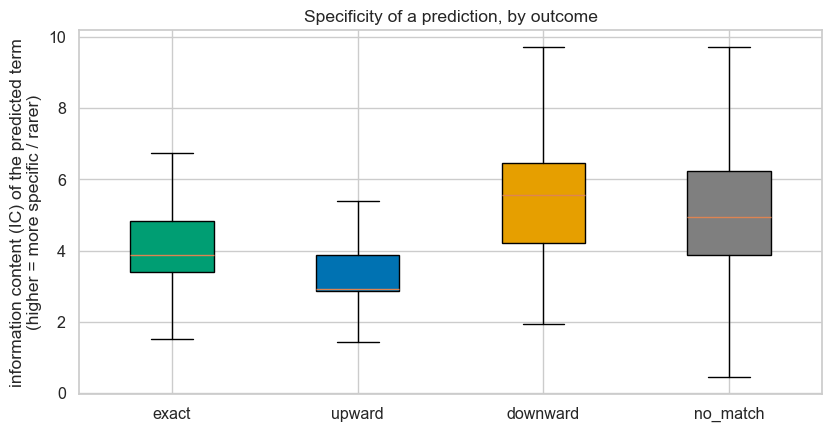

In [16]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
bp = ax.boxplot([P.loc[P["kind"] == k, "ic"].dropna() for k in ORDER], tick_labels=ORDER, patch_artist=True, showfliers=False)
for patch, k in zip(bp["boxes"], ORDER):
    patch.set_facecolor(COLORS[k])
ax.set_ylabel("information content (IC) of the predicted term\n(higher = more specific / rarer)"); ax.set_title("Specificity of a prediction, by outcome")
print(P.groupby("kind")["ic"].median().reindex(ORDER).round(2).to_string())
fig.tight_layout(); save(fig, "arm2_15_ic_by_outcome"); plt.show()

## 16. Is the match rate just tracking how well a gene is annotated?

A gene with many known true terms offers more chances to match. Left: the share of genes with a real match against the
number of known true terms. Right: matching predicted terms *per available true term*, which removes that effect. If the
left rises but the right does not, the trend is "more targets", not "better predictions".

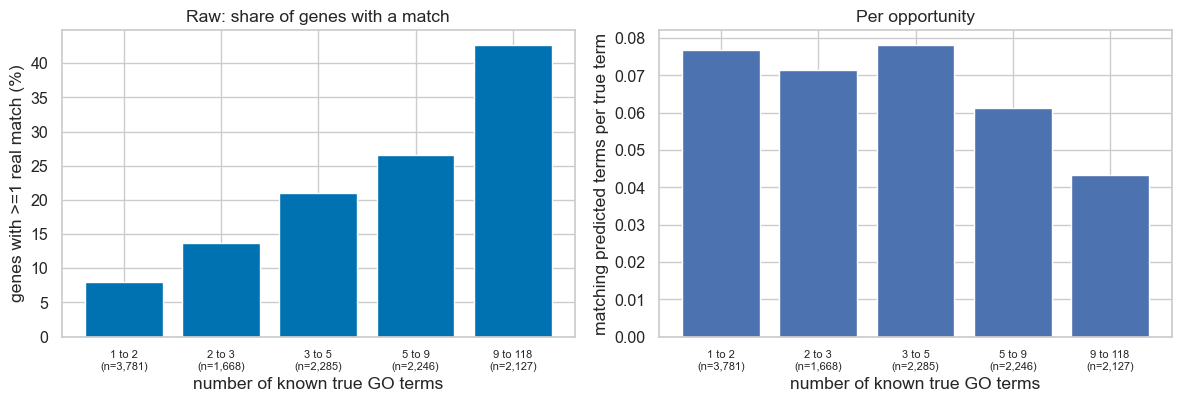

           match  per_term     n
bin                             
1 to 2    0.0796    0.0767  3781
2 to 3    0.1373    0.0715  1668
3 to 5    0.2105    0.0782  2285
5 to 9    0.2663    0.0612  2246
9 to 118  0.4269    0.0434  2127


In [17]:
d = G.dropna(subset=["n_direct_terms"]).copy(); d["bin"] = qbin(d["n_direct_terms"])
d["n_real"] = d["n_exact"] + d["n_upward"] + d["n_downward"]
t = d.groupby("bin", observed=True).agg(match=("any_match", "mean"), real=("n_real", "sum"), targets=("n_direct_terms", "sum"), n=("gene_id", "size"))
t = t.loc[sorted(t.index, key=lambda s: float(s.split(" to ")[0]))]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
x = np.arange(len(t)); lab = [f"{i}\n(n={n:,})" for i, n in zip(t.index, t["n"])]
ax1.bar(x, t["match"] * 100, color=COLORS["upward"]); ax1.set_xticks(x); ax1.set_xticklabels(lab, fontsize=8)
ax1.set_xlabel("number of known true GO terms"); ax1.set_ylabel("genes with >=1 real match (%)"); ax1.set_title("Raw: share of genes with a match")
ax2.bar(x, t["real"] / t["targets"], color=COLORS["volume"]); ax2.set_xticks(x); ax2.set_xticklabels(lab, fontsize=8)
ax2.set_xlabel("number of known true GO terms"); ax2.set_ylabel("matching predicted terms per true term"); ax2.set_title("Per opportunity")
fig.tight_layout(); save(fig, "arm2_16_annotation_richness"); plt.show()
print((t.assign(per_term=t["real"] / t["targets"])[["match", "per_term", "n"]]).round(4).to_string())

## 17. Does the ranking, or the model's own confidence, say anything about being right?

Each answer comes with a rank (first = the model's top choice) and a **confidence** the model wrote (between 0 and 1).
Left: the share of predicted terms that are real matches at each rank. Right: the same by the model's confidence. A
useful signal would fall from left to right on the left plot and rise on the right one; flat bars mean neither carries
information about correctness. The dashed line is the overall rate.

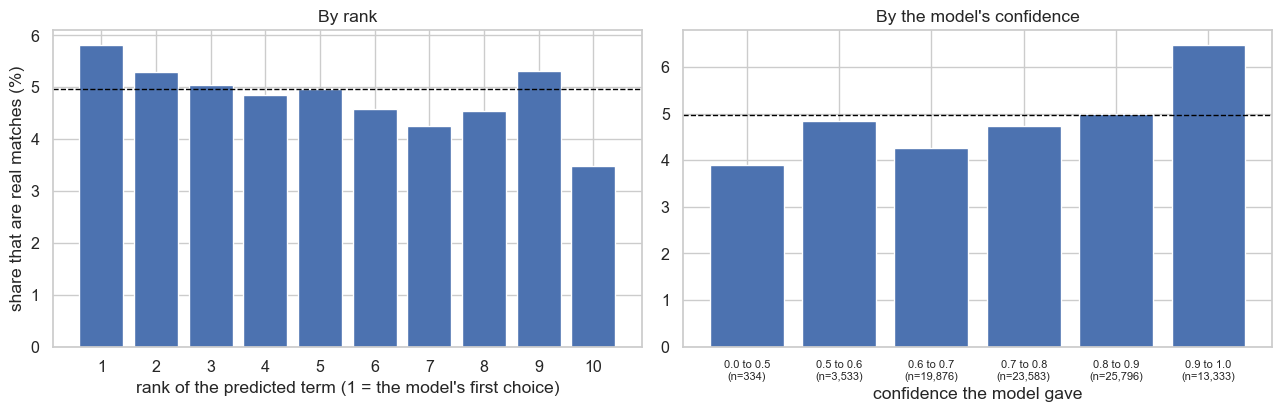

rate by rank: {1: 5.81, 2: 5.29, 3: 5.04, 4: 4.86, 5: 4.96, 6: 4.58, 7: 4.26, 8: 4.54, 9: 5.31, 10: 3.49}
rate by confidence bin: {'(-0.001, 0.5]': 3.89, '(0.5, 0.6]': 4.84, '(0.6, 0.7]': 4.26, '(0.7, 0.8]': 4.73, '(0.8, 0.9]': 5.0, '(0.9, 1.0]': 6.47}


In [18]:
real = (P["kind"] != "no_match")
overall = real.mean()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.3))
t = P.assign(real=real).groupby("rank").agg(rate=("real", "mean"), n=("real", "size")); t = t[t["n"] >= 100]
ax1.bar(t.index, t["rate"] * 100, color=COLORS["volume"]); ax1.axhline(overall * 100, color="black", linestyle="--", linewidth=1)
ax1.set_xlabel("rank of the predicted term (1 = the model's first choice)"); ax1.set_ylabel("share that are real matches (%)"); ax1.set_xticks(t.index)
ax1.set_title("By rank")
cf = P.dropna(subset=["confidence"]).copy(); cf["confidence"] = pd.to_numeric(cf["confidence"], errors="coerce")
cf = cf.dropna(subset=["confidence"]); cf["bin"] = pd.cut(cf["confidence"], [-0.001, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
tc = cf.assign(real=cf["kind"] != "no_match").groupby("bin", observed=True).agg(rate=("real", "mean"), n=("real", "size"))
ax2.bar(range(len(tc)), tc["rate"] * 100, color=COLORS["volume"]); ax2.axhline(overall * 100, color="black", linestyle="--", linewidth=1)
ax2.set_xticks(range(len(tc))); ax2.set_xticklabels([f"{max(iv.left, 0):.1f} to {iv.right:.1f}\n(n={n:,})" for iv, n in zip(tc.index, tc["n"])], fontsize=8)
ax2.set_xlabel("confidence the model gave"); ax2.set_title("By the model's confidence")
fig.tight_layout(); save(fig, "arm2_17_calibration"); plt.show()
print("rate by rank:", (t["rate"] * 100).round(2).to_dict()); print("rate by confidence bin:", {str(k): round(v * 100, 2) for k, v in tc["rate"].items()})

## 18. Which terms does the model predict, and how varied are its answers?

Left: the 20 terms predicted most often, with the share of each one's predictions that are real matches (split by kind).
Right: how concentrated the answers are, for the model and for arm 1: the share of all predicted terms taken by the 10
most frequent ones, and how many different terms occur at all. A model that repeats the same few terms is less
informative about the individual gene.

       distinct terms  share of all predictions taken by the 10 most frequent terms
arm 1              49                                                         0.774
arm 2             416                                                         0.346


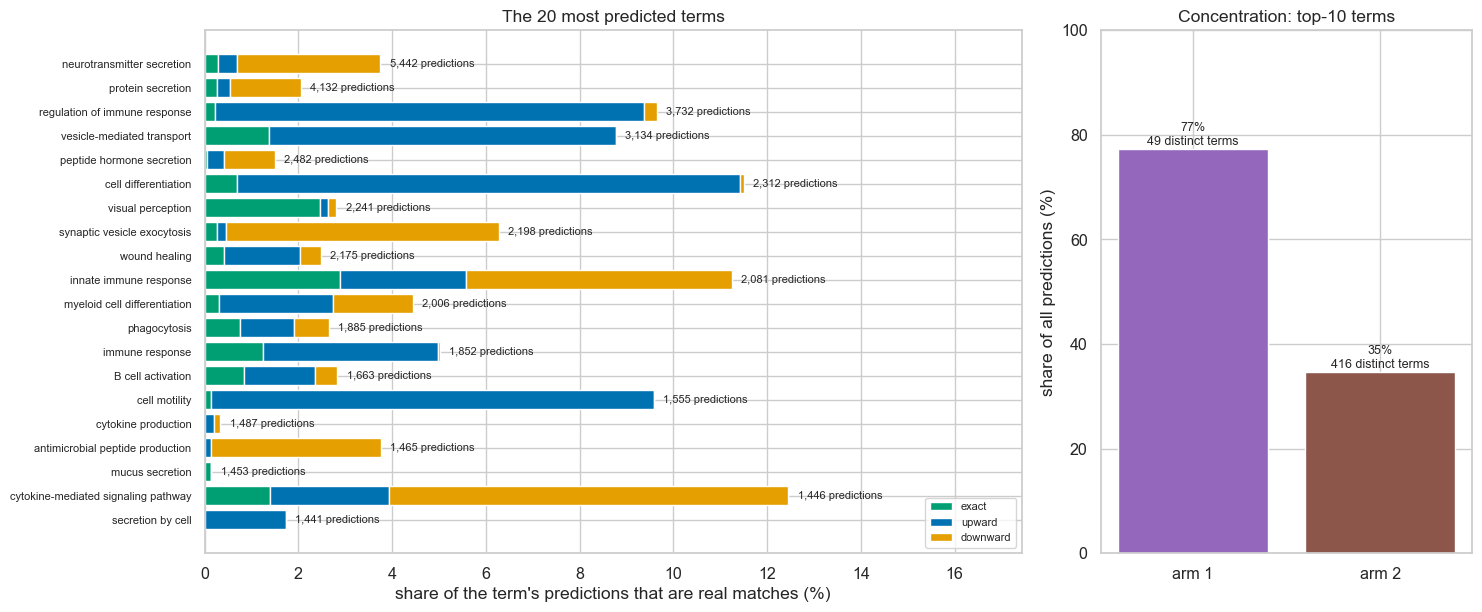

In [19]:
vc = P["label"].value_counts()
top = vc.head(20)[::-1]
rows = []
for lab in top.index:
    s = P[P["label"] == lab]["kind"].value_counts(normalize=True).reindex(["exact", "upward", "downward"]).fillna(0)
    rows.append(s)
tab = pd.DataFrame(rows, index=top.index)
a1v = arm1.sig["label"].value_counts()
stats_ = pd.DataFrame({"distinct terms": [len(a1v), len(vc)], "share of all predictions taken by the 10 most frequent terms": [a1v.head(10).sum() / a1v.sum(), vc.head(10).sum() / vc.sum()]}, index=["arm 1", "arm 2"])
print(stats_.round(3).to_string())
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.3), gridspec_kw={"width_ratios": [2.2, 1]})
left = np.zeros(len(tab))
for k in ["exact", "upward", "downward"]:
    ax1.barh(range(len(tab)), tab[k].values * 100, left=left * 100, color=COLORS[k], label=k); left += tab[k].values
for i, (lab, n) in enumerate(top.items()):
    ax1.text(left[i] * 100 + 0.2, i, f"{n:,} predictions", va="center", fontsize=8)
ax1.set_yticks(range(len(tab))); ax1.set_yticklabels([l if len(l) < 55 else l[:52] + "..." for l in tab.index], fontsize=8)
ax1.set_xlabel("share of the term's predictions that are real matches (%)"); ax1.legend(loc="lower right", fontsize=8)
ax1.set_xlim(0, max(left.max() * 100 * 1.4, 5)); ax1.set_title("The 20 most predicted terms")
ax2.bar(["arm 1", "arm 2"], stats_["share of all predictions taken by the 10 most frequent terms"] * 100, color=[COLORS["arm1"], COLORS["arm2"]])
for i, (s_, n_) in enumerate(zip(stats_["share of all predictions taken by the 10 most frequent terms"], stats_["distinct terms"])):
    ax2.text(i, s_ * 100 + 0.8, f"{s_:.0%}\n{int(n_):,} distinct terms", ha="center", fontsize=9)
ax2.set_ylim(0, 100); ax2.set_ylabel("share of all predictions (%)"); ax2.set_title("Concentration: top-10 terms")
fig.tight_layout(); save(fig, "arm2_18_vocabulary"); plt.show()

## 19. Are the matches concentrated in a few gene families?

HGNC gene families among the genes with at least one real match, against the share of the same families among all
finished genes. Bars much longer than the grey ones mean the family is over-represented among the matches.

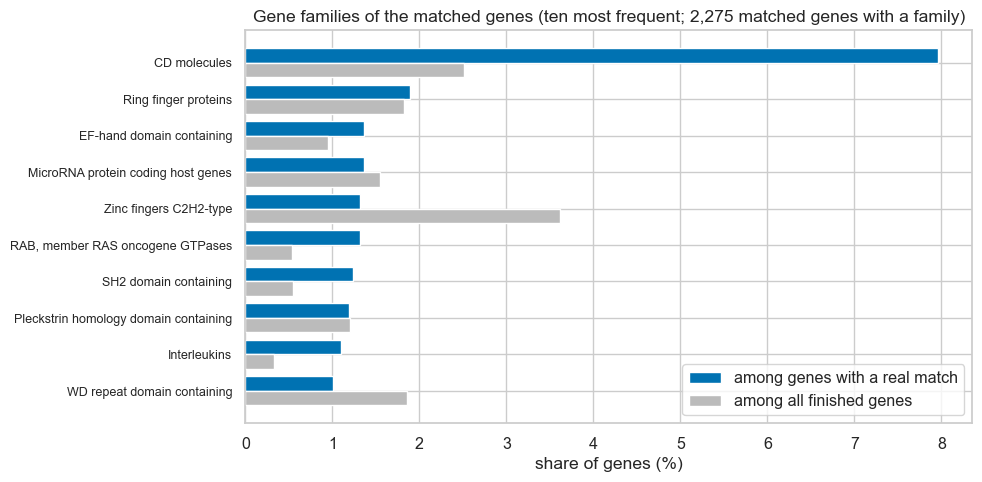

In [20]:
d = G.dropna(subset=["gene_group"]).copy()
m = d[d["any_match"] == 1]["gene_group"].value_counts(); a = d["gene_group"].value_counts()
top = m.head(10).index[::-1]
fig, ax = plt.subplots(figsize=(10, 5)); y = np.arange(len(top))
ax.barh(y + 0.2, [m[k] / m.sum() * 100 for k in top], height=0.4, color=COLORS["upward"], label="among genes with a real match")
ax.barh(y - 0.2, [a[k] / a.sum() * 100 for k in top], height=0.4, color="#BBBBBB", label="among all finished genes")
ax.set_yticks(y); ax.set_yticklabels([k if len(k) < 50 else k[:47] + "..." for k in top], fontsize=9)
ax.set_xlabel("share of genes (%)"); ax.legend(); ax.set_title(f"Gene families of the matched genes (ten most frequent; {m.sum():,} matched genes with a family)")
fig.tight_layout(); save(fig, "arm2_19_gene_families"); plt.show()

## 20. How far off are the matches in specificity, and what do the downward matches attach to?

Left: for non-exact matches, IC(true term) minus IC(predicted term): positive when the prediction is too general
(upward), negative when it is too specific (downward). Right: the true terms that downward matches attach to (the
gene's own, more general, annotation): a downward match is only possible against a fairly general true term.

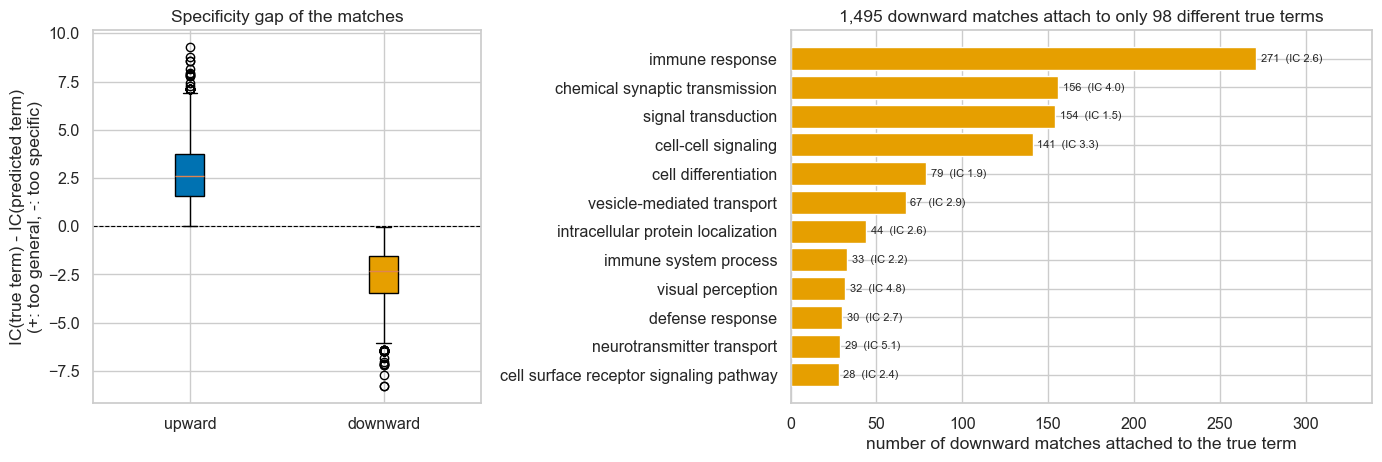

upward matches that are ALSO more specific than another true term of the gene: 91 of 2209
median IC gap: upward +2.60, downward -2.31
top 5 true terms cover 54% of the downward matches


In [21]:
mm = P[P["kind"].isin(["upward", "downward"])]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1.5]})
bp = ax1.boxplot([mm.loc[mm["kind"] == k, "ic_gap"].dropna() for k in ["upward", "downward"]], tick_labels=["upward", "downward"], patch_artist=True)
for patch, k in zip(bp["boxes"], ["upward", "downward"]):
    patch.set_facecolor(COLORS[k])
ax1.axhline(0, color="black", linestyle="--", linewidth=0.8)
ax1.set_ylabel("IC(true term) - IC(predicted term)\n(+: too general, -: too specific)"); ax1.set_title("Specificity gap of the matches")
dn = DET[DET["kind"] == "downward"]
tt = dn.groupby("true_label").agg(n=("gene_id", "size"), ic=("ic_true", "first")).sort_values("n", ascending=False)
top = tt.head(12)[::-1]
ax2.barh([l if len(l) < 45 else l[:42] + "..." for l in top.index], top["n"], color=COLORS["downward"])
for i, (n, ic) in enumerate(zip(top["n"], top["ic"])):
    ax2.text(n + tt["n"].max() * 0.01, i, f"{n}  (IC {ic:.1f})", va="center", fontsize=8)
ax2.set_xlim(0, tt["n"].max() * 1.25); ax2.set_xlabel("number of downward matches attached to the true term")
ax2.set_title(f"{len(dn):,} downward matches attach to only {len(tt)} different true terms")
fig.tight_layout(); save(fig, "arm2_20_ic_gap_and_downward"); plt.show()
print(f"upward matches that are ALSO more specific than another true term of the gene: {int(DET[DET.kind=='upward']['also_more_specific_than_other_true_term'].sum())} of {int((DET.kind=='upward').sum())}")
print(f"median IC gap: upward {mm[mm.kind=='upward']['ic_gap'].median():+.2f}, downward {mm[mm.kind=='downward']['ic_gap'].median():+.2f}")
print(f"top 5 true terms cover {tt['n'].head(5).sum() / tt['n'].sum():.0%} of the downward matches")

## Part 4 summary

- **Plot 14, expression breadth.** The share of genes with a real match is 27.6% for the narrowest genes, 16.6% in the middle
  and 19.9% for the broadest; the share with an exact match falls from 8.7% to about 2.8%.
  *For us:* exact matches depend strongly on breadth (about three times as many for narrow genes). The rise in the real-match
  rate for the broadest genes is the generic effect from Part 3, not a skill.
- **Plot 15, specificity of the predictions.** Median IC is 3.9 for exact, 2.9 for upward, 5.6 for downward and 4.9 for
  no_match terms.
  *For us:* the model's exact matches are less specific than its average wrong answer, so its wins are moderately general terms.
- **Plot 16, annotation richness.** The share of genes with a match rises from 8.0% to 42.7% with the number of known true
  terms, but the number of matching terms per available true term falls from 0.077 to 0.043.
  *For us:* well-annotated genes offer more chances to match, not better predictions, as in arm 1.
- **Plot 17, rank and confidence.** The first choice is a real match 5.8% of the time (overall 5.0%) and the tenth 3.5%; by
  confidence the rate is 3.9% at 0.5 or below, 4.3-5.0% in the middle and 6.5% for confidence above 0.9.
  *For us:* the model's ordering and its highest confidence carry a weak signal (about 1.3 times the average), unlike arm 1's
  ranking, but far too weak to filter its answers.
- **Plot 18, vocabulary.** The model uses 416 different terms against 49 for arm 1, and its 10 most frequent terms take 35%
  of its predictions against 77% for arm 1. The most predicted terms are neurotransmitter secretion (5,442), protein
  secretion (4,132) and regulation of immune response (3,732); their precision runs from near 0 to about 12%.
  *For us:* the model is much more varied than arm 1, but a handful of generic terms still dominate and most of them are
  rarely right.
- **Plot 19, gene families.** CD molecules are 8.0% of the matched genes against 2.5% of all genes; zinc finger C2H2 genes
  are under-represented (1.3% against 3.6%).
  *For us:* the matches still lean toward well-annotated immune gene families.
- **Plot 20, specificity gap and downward matches.** Upward matches are too general by a median of 2.6 IC units, downward too
  specific by 2.3. The 1,495 downward matches attach to only 98 different true terms; immune response (271), chemical
  synaptic transmission (156), signal transduction (154) and cell-cell signaling (141) lead, and the top five cover 54%.
  91 of the 2,209 upward matches are also more specific than another true term of the same gene.
  *For us:* as in arm 1, downward matches are only possible against general true terms. With a baseline ratio of 1.38x they
  are mostly easy targets and should be reported separately from exact and upward matches.

# Part 5 — The language model against arm 1, on the same genes

Both arms are scored the same way, against the same true terms, on the genes both have results for. To compare them
fairly the output size has to be equal: arm 1 often reports 0 or 1 terms, the model up to 10. So the comparison asks, for
each gene, whether the **top 1, top 3 or top 10** terms contain at least one real match. A gene for which arm 1 reports no
significant term counts as "no match" for arm 1: it has no answer.

## 21. Chance of a real match within the top 1, 3 and 10 terms

For each arm, the share of genes whose top-k terms contain at least one real match (left) and at least one exact match
(right), on the genes both arms have results for.

genes with results in both arms: 12,044


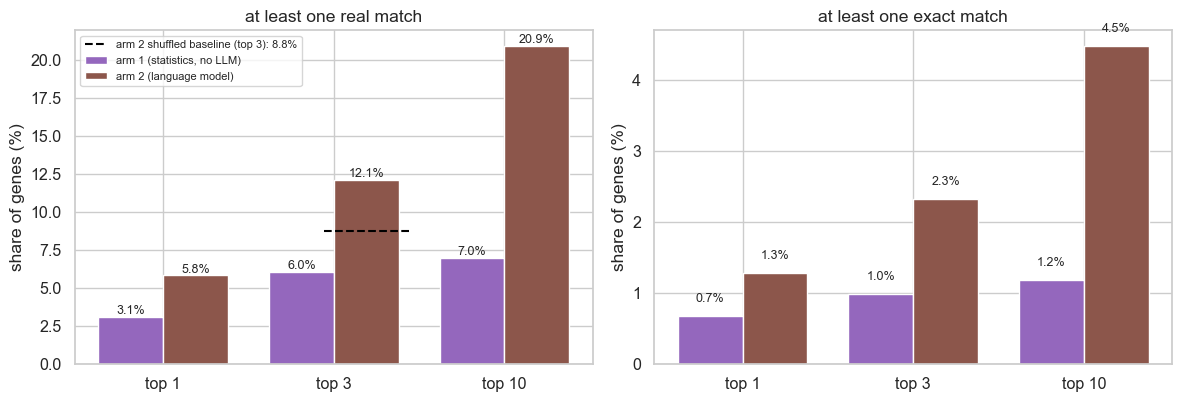

In [22]:
B = G[G["arm1_in_run"]].copy()
print(f"genes with results in both arms: {len(B):,}")
ks = [1, 3, 10]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=False)
for ax, pre, title in [(axes[0], "match", "at least one real match"), (axes[1], "exact", "at least one exact match")]:
    x = np.arange(len(ks)); w = 0.38
    v1 = [B[f"arm1_{pre}_at_{k}"].mean() * 100 for k in ks]; v2 = [B[f"{pre}_at_{k}"].mean() * 100 for k in ks]
    ax.bar(x - w / 2, v1, width=w, color=COLORS["arm1"], label="arm 1 (statistics, no LLM)"); ax.bar(x + w / 2, v2, width=w, color=COLORS["arm2"], label="arm 2 (language model)")
    for i, (a, b) in enumerate(zip(v1, v2)):
        ax.text(i - w / 2, a + 0.2, f"{a:.1f}%", ha="center", fontsize=9); ax.text(i + w / 2, b + 0.2, f"{b:.1f}%", ha="center", fontsize=9)
    if pre == "match":   # shuffled-prediction baseline exists for the top 3 only
        sb = B["shuf_match_at_3"].mean() * 100
        ax.hlines(sb, 1 + w / 2 - 0.25, 1 + w / 2 + 0.25, color="black", linestyle="--", linewidth=1.5, label=f"arm 2 shuffled baseline (top 3): {sb:.1f}%")
    ax.set_xticks(x); ax.set_xticklabels([f"top {k}" for k in ks]); ax.set_ylabel("share of genes (%)"); ax.set_title(title)
axes[0].legend(fontsize=8)
fig.tight_layout(); save(fig, "arm2_21_match_at_k"); plt.show()

## 22. The same comparison by expression breadth

Share of genes with at least one real match in the top 3 terms, for each arm, in five equal-sized groups of expression
breadth. Shows where each method works and whether the model helps where arm 1 has nothing (broadly expressed genes).
The dashed line on each arm-2 bar is the shuffled baseline from Part 3 (what the same answers would score against other
genes): only the part of a bar above that line is evidence of gene-specific information.

                   arm1  arm2  shuf     n
bin                                      
0.000393 to 0.201  13.7  18.3   8.9  2409
0.201 to 0.568     10.2  13.7   9.2  2409
0.568 to 0.871      4.2   7.9   6.5  2408
0.871 to 0.967      1.6   8.7   7.3  2425
0.967 to 1          0.3  11.8  11.9  2393


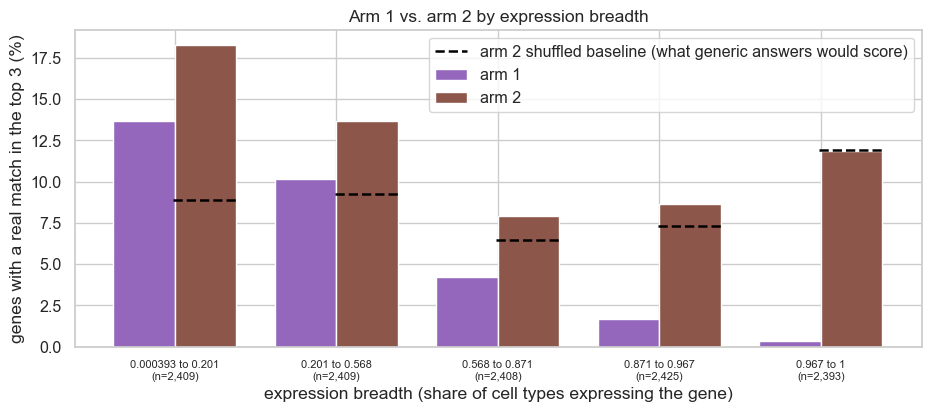

In [23]:
d = B.dropna(subset=["breadth"]).copy(); d["bin"] = qbin(d["breadth"])
t = d.groupby("bin", observed=True).agg(arm1=("arm1_match_at_3", "mean"), arm2=("match_at_3", "mean"), shuf=("shuf_match_at_3", "mean"), n=("gene_id", "size"))
t = t.loc[sorted(t.index, key=lambda s: float(s.split(" to ")[0]))]
print((t[["arm1", "arm2", "shuf"]] * 100).round(1).assign(n=t["n"]).to_string())
fig, ax = plt.subplots(figsize=(9.5, 4.3)); x = np.arange(len(t)); w = 0.38
ax.bar(x - w / 2, t["arm1"] * 100, width=w, color=COLORS["arm1"], label="arm 1"); ax.bar(x + w / 2, t["arm2"] * 100, width=w, color=COLORS["arm2"], label="arm 2")
ax.hlines(t["shuf"] * 100, x + w / 2 - 0.2, x + w / 2 + 0.2, color="black", linestyle="--", linewidth=1.8, label="arm 2 shuffled baseline (what generic answers would score)")
ax.set_xticks(x); ax.set_xticklabels([f"{i}\n(n={n:,})" for i, n in zip(t.index, t["n"])], fontsize=8)
ax.set_xlabel("expression breadth (share of cell types expressing the gene)"); ax.set_ylabel("genes with a real match in the top 3 (%)"); ax.legend()
ax.set_title("Arm 1 vs. arm 2 by expression breadth")
fig.tight_layout(); save(fig, "arm2_22_by_breadth_both_arms"); plt.show()

## 23. Do the two arms succeed on the same genes?

For each gene: did only arm 1, only arm 2, both, or neither get a real match in the top 3 (left), and an exact match in
the top 3 (right)? If the arms were interchangeable almost all successes would be "both"; large "only" groups mean they
find different genes, so a combination could beat either alone.

real match in the top 3 {'both': 524, 'only arm 2': 930, 'only arm 1': 200, 'neither': 10390}
exact match in the top 3 {'both': 92, 'only arm 2': 188, 'only arm 1': 27, 'neither': 11737}


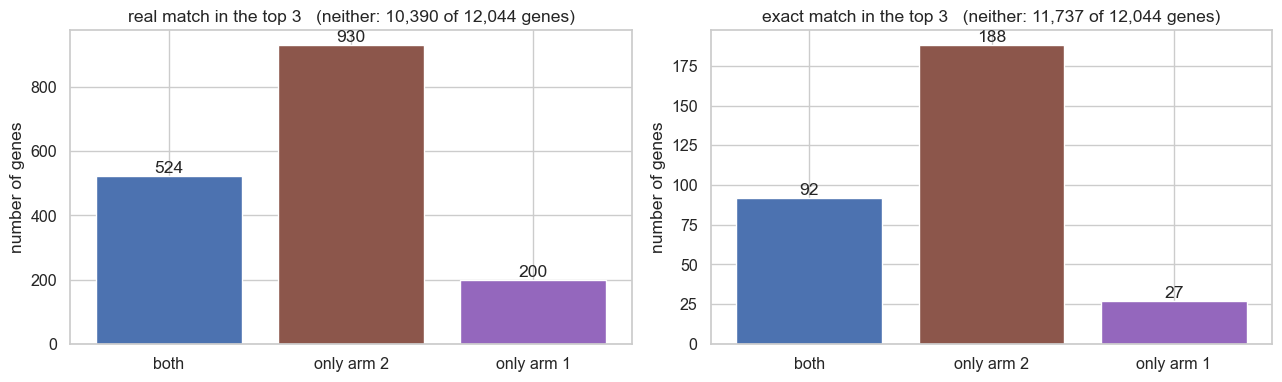

In [24]:
def four(a, b):
    return pd.Series({"both": int(((a == 1) & (b == 1)).sum()), "only arm 2": int(((a == 0) & (b == 1)).sum()),
                      "only arm 1": int(((a == 1) & (b == 0)).sum()), "neither": int(((a == 0) & (b == 0)).sum())})
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (a, b, title) in zip(axes, [(B["arm1_match_at_3"], B["match_at_3"], "real match in the top 3"), (B["arm1_exact_at_3"], B["exact_at_3"], "exact match in the top 3")]):
    f = four(a, b); show = f.drop("neither")
    bars = ax.bar(show.index, show.values, color=[COLORS["volume"], COLORS["arm2"], COLORS["arm1"]])
    for bar, v in zip(bars, show.values):
        ax.text(bar.get_x() + bar.get_width() / 2, v + show.max() * 0.01, f"{v:,}", ha="center")
    ax.set_title(f"{title}   (neither: {f['neither']:,} of {len(B):,} genes)"); ax.set_ylabel("number of genes")
    print(title, f.to_dict())
fig.tight_layout(); save(fig, "arm2_23_complementarity"); plt.show()

## Part 5 summary

- **Plot 21, top 1, 3 and 10.** At least one real match in the top 1 / 3 / 10 terms: arm 1 3.1% / 6.0% / 7.0%, arm 2 5.8% /
  12.1% / 20.9%. For an exact match: arm 1 0.7% / 1.0% / 1.2%, arm 2 1.3% / 2.3% / 4.5%. The shuffled baseline for arm 2 in the
  top 3 is 8.8%.
  *For us:* at equal output size the model finds about twice as many genes with a real match and 2 to 4 times as many with an
  exact one. About 8.8 of its 12.1 points in the top 3 would also come from generic answers, so its gene-specific gain
  in that column is about 3 points. Arm 1 has its own chance reference (in the arm-1 notebook), built differently, so the
  two baselines are not the same measure.
- **Plot 22, by expression breadth.** Real match in the top 3, arm 1 against arm 2 (baseline for arm 2): 13.7 against 18.3
  (8.9) for the narrowest genes, 10.2 against 13.7 (9.2), 4.2 against 7.9 (6.5), 1.6 against 8.7 (7.3) and 0.3 against 11.8
  (11.9) for the broadest.
  *For us:* on narrow genes the model beats arm 1 and clearly beats generic answers. On broad genes its apparent advantage over
  arm 1 is entirely generic: at the broadest the model is at its baseline, while arm 1 has almost nothing.
- **Plot 23, complementarity.** Real match in the top 3: both arms 524 genes, only arm 2 930, only arm 1 200, neither 10,390
  (of 12,044). Exact match: both 92, only arm 2 188, only arm 1 27.
  *For us:* the model finds most of what arm 1 finds (524 of 724 genes) and adds many more, though some of the "only arm 2"
  genes are generic matches. Arm 1 still finds 200 genes the model misses, so a combination of the two could add a little.

# Part 6 — What does a run cost?

## 24. Time and prompt size per gene

Left: how long one gene took (time for the model call, from the saved runs). Right: the size of the prompt in tokens.
The title gives the implied time to finish the remaining genes at the median speed. The server was shared and its speed
varied a lot over the run, so this is a rough figure. The prompt size stops at about 4,040 tokens because that is the
size of the full table of 52 evidence terms, the largest prompt possible; it is not a cut-off (the model's context window
is 262,144 tokens, of which a prompt uses about 1.5%).

context window used by a prompt: median 1.5%, maximum 1.5% (nothing is truncated)
full set of 15,944 scoreable genes at the median: about 109 hours of model time


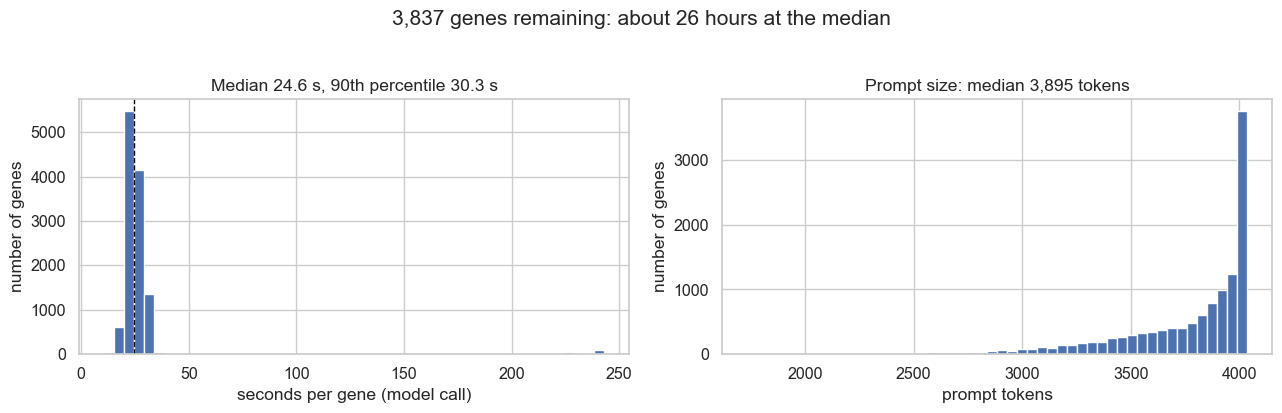

In [25]:
cost = R["cost"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
lat = G["latency_s"].dropna()
ax1.hist(lat.clip(upper=lat.quantile(0.995)), bins=50, color=COLORS["volume"], edgecolor="white")
ax1.axvline(lat.median(), color="black", linestyle="--", linewidth=1); ax1.set_xlabel("seconds per gene (model call)"); ax1.set_ylabel("number of genes")
ax1.set_title(f"Median {lat.median():.1f} s, 90th percentile {lat.quantile(0.9):.1f} s")
tk = G["actual_prompt_tokens"].dropna()
ax2.hist(tk, bins=50, color=COLORS["volume"], edgecolor="white"); ax2.set_xlabel("prompt tokens"); ax2.set_ylabel("number of genes")
ax2.set_title(f"Prompt size: median {tk.median():,.0f} tokens")
print(f"context window used by a prompt: median {c2.done['context_utilization'].median():.1%}, maximum {c2.done['context_utilization'].max():.1%} (nothing is truncated)")
print(f"full set of {cost['n_universe']:,} scoreable genes at the median: about {cost['n_universe'] * lat.median() / 3600:.0f} hours of model time")
fig.suptitle(f"{cost['n_remaining']:,} genes remaining: about {cost['remaining_hours_at_median']:.0f} hours at the median", y=1.03)
fig.tight_layout(); save(fig, "arm2_24_cost"); plt.show()

## Part 6 summary

- **Plot 24, cost.** A gene takes a median of 24.6 s (90th percentile 30.3 s) and the prompt has a median of 3,895 tokens,
  at most about 4,040 (the full table). That is about 1.5% of the model's context window, so nothing is truncated. The
  3,837 remaining genes need about 26 hours at the median.
  *For us:* the cost per gene is steady, about 109 hours of model time for all 15,944 scoreable genes. The wall-clock time of
  the run has been much longer because the shared server's speed varied a lot.

# Taken together

The model writes valid GO terms reliably, about 7 per gene, and with equal output size finds a real match for about twice as
many genes as arm 1. But most of its matches would also occur with generic answers: its gene-specific information is clear for
narrowly expressed genes and absent for the most broadly expressed ones, its per-term precision is no better than arm 1's, and
its confidence is only weakly informative.

**Limits of this analysis.** Only the condition with the real evidence has been run, so "does the model use the evidence?" is
answered only through the shuffled baseline, not through the real control (evidence from a different gene, or no evidence).
One model was used. Matching is against GOA annotations, part of which is inferred, not measured. The finished genes are the
first part of the run; the coverage notebook shows how representative they are, and the numbers here must be refreshed when
the run completes.